In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("stops.csv")

display(df.head())
df.info()

,uid,code,label,description,lat,lon,CATUTTC,addressPostCode,addressAdminUnitL1,addressAdminUnitL2,...,addressPostName,addressThoroughfare,addressLocatorDesignator,addressDescription,zoneId,url,type,parentStation,timezone,wheelchairBoarding
0,4711,320,ТРЦ Кінг Кросс (320),NaN,49.774093,24.012718,UA46060250010015970,79000,Україна,Львівська область,...,Львів,вул. Стрийська,30,NaN,0,NaN,0,NaN,Europe/Kyiv,0
1,4712,434,Іподром (434),NaN,49.778119,24.014171,UA46060250010015970,79000,Україна,Львівська область,...,Львів,вул. Стрийська,179,NaN,0,NaN,0,NaN,Europe/Kyiv,0
2,4713,435,Сокільницька (435),NaN,49.784229,24.014322,UA46060250010015970,79000,Україна,Львівська область,...,Львів,вул. Стрийська,197,NaN,0,NaN,0,NaN,Europe/Kyiv,0
3,4714,433,Автовокзал (433),NaN,49.787405,24.017618,UA46060250010015970,79000,Україна,Львівська область,...,Львів,вул. Стрийська,109,NaN,0,NaN,0,NaN,Europe/Kyiv,0
4,4715,432,Максимовича (432),NaN,49.792621,24.016092,UA46060250010015970,79000,Україна,Львівська область,...,Львів,вул. Стрийська,71,NaN,0,NaN,0,NaN,Europe/Kyiv,0


<class 'pandas.DataFrame'>
RangeIndex: 1034 entries, 0 to 1033
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   uid                       1034 non-null   int64  
 1   code                      1034 non-null   str    
 2   label                     1034 non-null   str    
 3   description               0 non-null      float64
 4   lat                       1034 non-null   float64
 5   lon                       1034 non-null   float64
 6   CATUTTC                   1034 non-null   str    
 7   addressPostCode           1034 non-null   int64  
 8   addressAdminUnitL1        1034 non-null   str    
 9   addressAdminUnitL2        1034 non-null   str    
 10  addressAdminUnitL3        1034 non-null   str    
 11  addressAdminUnitL4        1034 non-null   str    
 12  addressPostName           1034 non-null   str    
 13  addressThoroughfare       1007 non-null   str    
 14  addressLocatorDesig

In [52]:
# data cleanup
df.dropna(subset=['lat', 'lon'])

df = df[(df['lat'] > 49.0) & (df['lon'] > 23.0)]

print(f"Quantity of stops for the analysis: {len(df)}")

Quantity of stops for the analysis: 1034


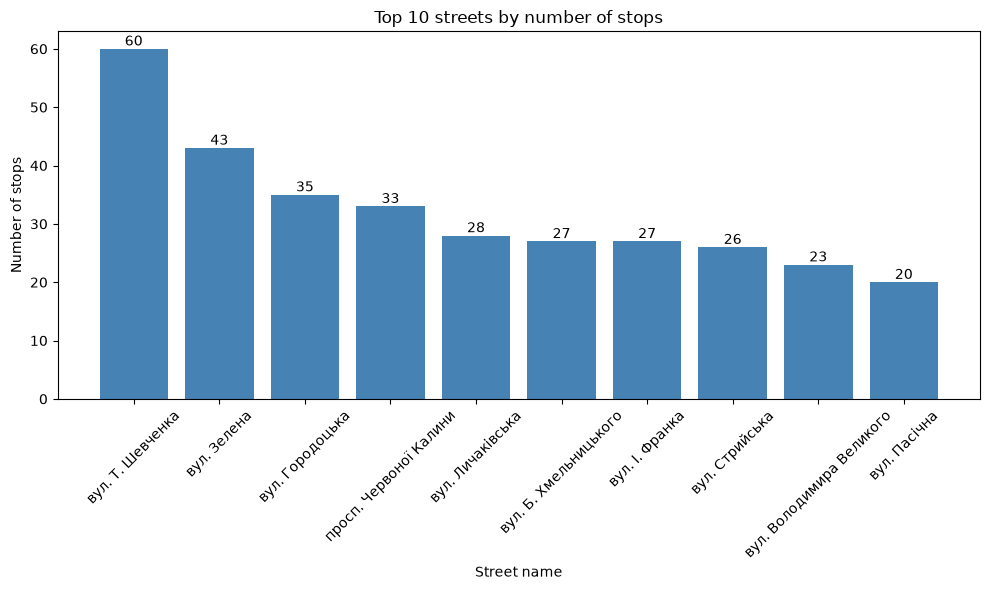

In [53]:
top_stops = df["addressThoroughfare"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(top_stops.index, top_stops.values, color="steelblue")

ax.bar_label(bars, padding=0)
ax.set_title("Top 10 streets by number of stops")
ax.set_xlabel("Street name")
ax.set_ylabel("Number of stops")
ax.tick_params(axis="x", labelrotation=45)

fig.tight_layout()
plt.show()

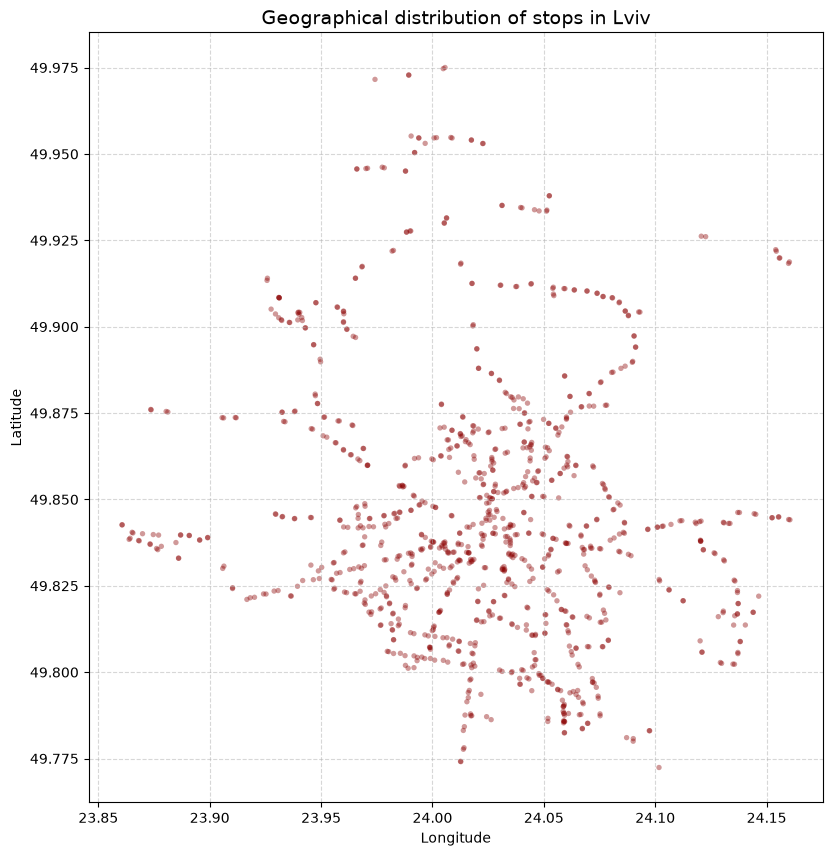

In [54]:
plt.figure(figsize=(12,10))
plt.scatter(df['lon'], df['lat'], alpha=0.4, s=15, c='darkred', edgecolors='none')

plt.title("Geographical distribution of stops in Lviv", fontsize=14)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True, linestyle='--', alpha=0.5)

mean_lat = df["lat"].mean()
# Compensate for longitude degrees being shorter than latitude degrees.
plt.gca().set_aspect(1 / np.cos(np.deg2rad(mean_lat)), adjustable="box")
plt.show()

Number of stops outside the main city: 254
Number of other settlements: 19


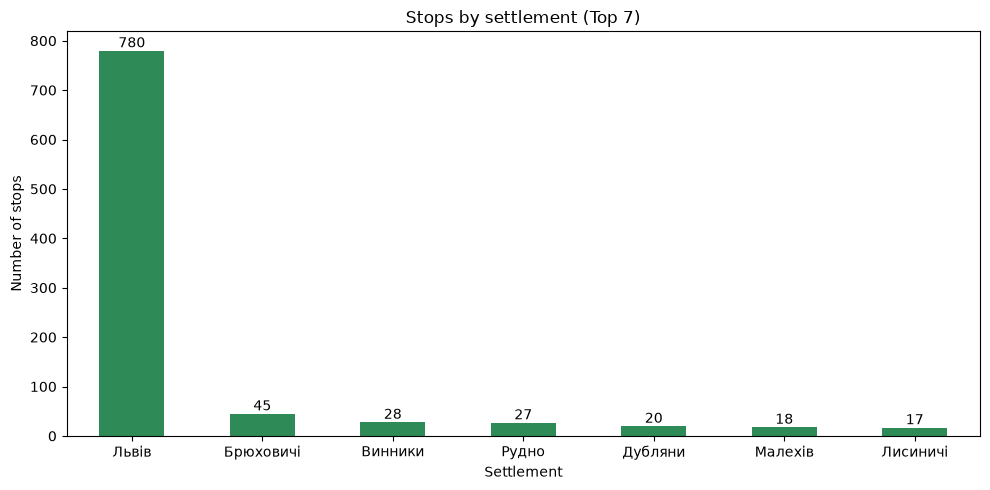

In [62]:
settlement_counts = df["addressPostName"].value_counts()  # counts stops per settlement

top_7 = settlement_counts.head(7)

# Index 0 is the main city, so iloc[1:] takes all other settlements
other_stops = settlement_counts.iloc[1:].sum()

print(f"Number of stops outside the main city: {other_stops}")
print(f"Number of other settlements: {len(settlement_counts.iloc[1:])}")

fig, ax = plt.subplots(figsize=(10, 5))
top_7.plot(kind="bar", ax=ax, color="seagreen")
ax.bar_label(ax.containers[0], padding=0)

ax.set_title("Stops by settlement (Top 7)")
ax.set_xlabel("Settlement")
ax.set_ylabel("Number of stops")
ax.tick_params(axis="x", labelrotation=0)

fig.tight_layout()
plt.show()